In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.plotting.register_matplotlib_converters()
%matplotlib inline

candy_data = pd.read_csv("../datasets/data-for-datavis/candy.csv", index_col="id")

In [15]:
from IPython.display import display, Markdown

content = f"""
## Dataset

- **competitorname**: contains the name of the candy bar.
- **chocolate** to **pluribus**: describe the candy; e.g.: rows with chocolate candies have "Yes" in the 'chocolate' column, candies without chocolate have "No".
- **sugarpercent**: provides some indication of the amount of sugar, where higher values signify higher sugar content.
- **pricepercent**: shows the price per unit, relative to the other candies in the dataset.
- **winpercent**: calculated from the survey results; higher values indicate that the candy was more popular with survey respondents.

{candy_data.head().to_markdown()}

.
"""
display(Markdown(content))



## Dataset

- **competitorname**: contains the name of the candy bar.
- **chocolate** to **pluribus**: describe the candy; e.g.: rows with chocolate candies have "Yes" in the 'chocolate' column, candies without chocolate have "No".
- **sugarpercent**: provides some indication of the amount of sugar, where higher values signify higher sugar content.
- **pricepercent**: shows the price per unit, relative to the other candies in the dataset.
- **winpercent**: calculated from the survey results; higher values indicate that the candy was more popular with survey respondents.

|   id | competitorname   | chocolate   | fruity   | caramel   | peanutyalmondy   | nougat   | crispedricewafer   | hard   | bar   | pluribus   |   sugarpercent |   pricepercent |   winpercent |
|-----:|:-----------------|:------------|:---------|:----------|:-----------------|:---------|:-------------------|:-------|:------|:-----------|---------------:|---------------:|-------------:|
|    0 | 100 Grand        | Yes         | No       | Yes       | No               | No       | Yes                | No     | Yes   | No         |          0.732 |          0.86  |      66.9717 |
|    1 | 3 Musketeers     | Yes         | No       | No        | No               | Yes      | No                 | No     | Yes   | No         |          0.604 |          0.511 |      67.6029 |
|    2 | Air Heads        | No          | Yes      | No        | No               | No       | No                 | No     | No    | No         |          0.906 |          0.511 |      52.3415 |
|    3 | Almond Joy       | Yes         | No       | No        | Yes              | No       | No                 | No     | Yes   | No         |          0.465 |          0.767 |      50.3475 |
|    4 | Baby Ruth        | Yes         | No       | Yes       | Yes              | Yes      | No                 | No     | Yes   | No         |          0.604 |          0.767 |      56.9145 |

.


In [3]:
# Which candy was more popular with survey respondents: '3 Musketeers' or 'Almond Joy'? 
more_popular = candy_data.loc[
    candy_data[candy_data.competitorname.isin(['3 Musketeers', 'Almond Joy'])].winpercent.idxmax()
].competitorname
more_popular

'3 Musketeers'

In [4]:
# Which candy has higher sugar content: 'Air Heads' or 'Baby Ruth'?
more_sugar = candy_data.loc[
    candy_data[candy_data.competitorname.isin(['Air Heads', 'Baby Ruth'])].sugarpercent.idxmax()
].competitorname
more_sugar

'Air Heads'

<Axes: xlabel='sugarpercent', ylabel='winpercent'>

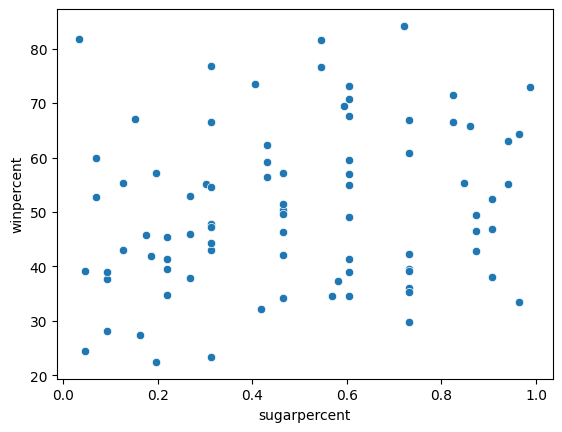

In [5]:
sns.scatterplot(x=candy_data.sugarpercent, y=candy_data.winpercent)

<Axes: xlabel='sugarpercent', ylabel='winpercent'>

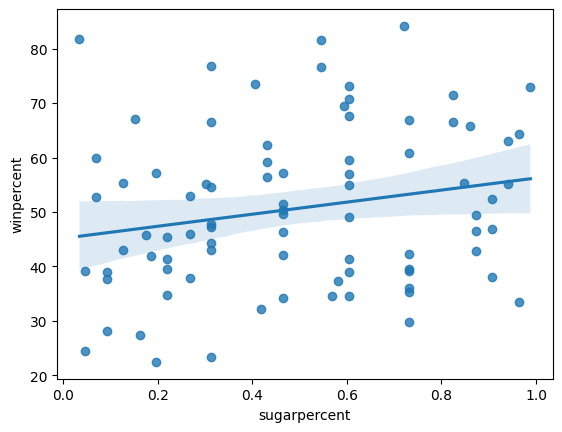

In [6]:
sns.regplot(x=candy_data.sugarpercent, y=candy_data.winpercent)

<Axes: xlabel='pricepercent', ylabel='winpercent'>

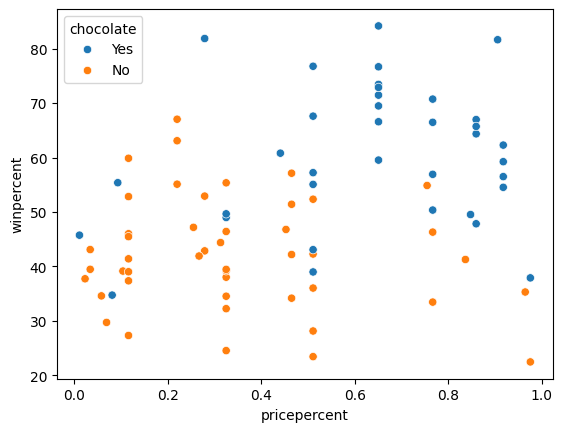

In [7]:
sns.scatterplot(x=candy_data.pricepercent, y=candy_data.winpercent, hue=candy_data.chocolate)

In [20]:
content = f"""
**Q**: According to the plot above, is there a slight correlation between **_winpercent_** and **_sugarpercent_**?
What does this tell you about the candy that people tend to prefer?<br>
**A**: The regression line has a slightly positive slope, which hints a slightly positive correlation 
between **_winpercent_** and **_sugarpercent_**. Thus, people have a slight preference for 
candies containing relatively more sugar.
"""

display(Markdown(content))



**Q**: According to the plot above, is there a slight correlation between **_winpercent_** and **_sugarpercent_**?
What does this tell you about the candy that people tend to prefer?<br>
**A**: The regression line has a slightly positive slope, which hints a slightly positive correlation 
between **_winpercent_** and **_sugarpercent_**. Thus, people have a slight preference for 
candies containing relatively more sugar.


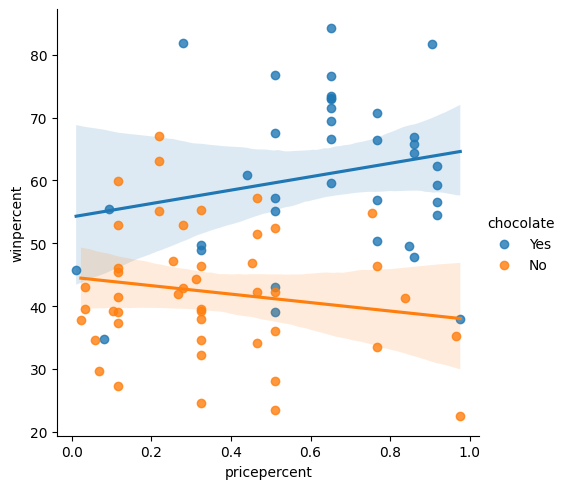

In [8]:
sns.lmplot(x="pricepercent", y="winpercent", hue="chocolate", data=candy_data)

In [23]:
content = f"""
**Q**: Using the regression lines, what conclusions can you draw about the effects of 
**_chocolate_** and **_price_** on candy popularity?<br>
**A**: We'll begin with the regression line for chocolate candies. Since this line has a slightly 
positive slope, we can say that more expensive chocolate candies tend to be more popular 
(than relatively cheaper chocolate candies). Likewise, since the regression line for candies 
without chocolate has a negative slope, we can say that if candies don't contain chocolate, 
they tend to be more popular when they are cheaper. One important note, however, is that the dataset 
is quite small ({candy_data.size} rows) -- so we shouldn't invest too much trust in these patterns! To inspire more confidence 
in the results, we should add more candies to the dataset.
"""

display(Markdown(content))


**Q**: Using the regression lines, what conclusions can you draw about the effects of 
**_chocolate_** and **_price_** on candy popularity?<br>
**A**: We'll begin with the regression line for chocolate candies. Since this line has a slightly 
positive slope, we can say that more expensive chocolate candies tend to be more popular 
(than relatively cheaper chocolate candies). Likewise, since the regression line for candies 
without chocolate has a negative slope, we can say that if candies don't contain chocolate, 
they tend to be more popular when they are cheaper. One important note, however, is that the dataset 
is quite small (1079 rows) -- so we shouldn't invest too much trust in these patterns! To inspire more confidence 
in the results, we should add more candies to the dataset.


<Axes: xlabel='chocolate', ylabel='winpercent'>

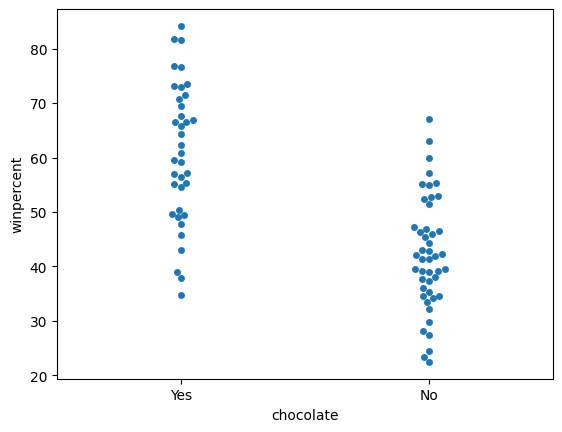

In [25]:
sns.swarmplot(x=candy_data.chocolate, y=candy_data.winpercent)